In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

folder = Path.cwd()
data = folder/"data"/"processed"
metrics = pd.read_csv(data/"client_metrics.csv", dtype={"client_id":"string", "branch_code":"string", "comparable":"boolean",
    "income_suspicious_low":"boolean", "client_record_conflict":"boolean", "declined":"boolean", "decline_both_windows":"boolean"})
months = pd.read_csv(data/"client_month.csv", dtype={"client_id":"string"})
ops = pd.read_csv(data/"transactions_analysis.csv", dtype={"client_id":"string", "txn_id":"string", "mcc_code":"string"}, parse_dates=["txn_datetime"])
campaign = pd.read_csv(folder/"campaign_list.csv", dtype="string")
log = pd.read_csv(folder/"cleaning_log.csv")
a = metrics.loc[metrics["comparable"]].copy()
members = a.merge(campaign, on="client_id", validate="one_to_one")
order = ["Массовый, без приложения", "Массовый, с приложением", "Зарплатный", "Премиальный + Private"]
short = ["Массовые без приложения", "Массовые с приложением", "Зарплатные", "Премиальные и Private"]
profile = members.groupby("group").agg(N=("client_id","size"), F24=("f24","median"), F25=("f25","median"),
    delta=("delta","median"), relative=("relative_change","median")).reindex(order)
plt.rcParams.update({"font.size":9,"figure.dpi":140,"axes.spines.top":False,"axes.spines.right":False})
mean24,mean25 = a["f24"].mean(), a["f25"].mean()
drop = (1-mean25/mean24)*100
h1_drop = (1-mean25/a["f24_h1"].mean())*100

mass=a.loc[a["segment"].eq("Массовый")].groupby("has_mobile_app")["declined"].agg(["size","sum","mean"])
assert len(metrics)==5668 and len(ops)==586526 and len(a)==5556
assert list(campaign.columns)==["client_id","group"] and campaign["client_id"].is_unique
assert len(members)==len(campaign)<=2000 and 3<=len(profile)<=5 and profile["N"].ge(150).all()
assert members["marketing_opt_in"].eq("Да").all() and members["decline_both_windows"].all()

# Разрывы страниц нужны только для печати отчета.
display(HTML("""<style>
@page { size: A4; margin: 10mm 12mm; }
@media print {
body { margin: 0; font-family: Arial, sans-serif; color: #111; }
.jp-Notebook { padding: 0 !important; }
.jp-Cell { padding: 0 !important; margin: 0 !important; }
.jp-Cell:has(.report-page-start) { break-before: page; }
.jp-RenderedHTMLCommon { font-size: 9.4pt; line-height: 1.3; }
.jp-RenderedHTMLCommon p { margin: 0 0 6pt; }
.jp-RenderedHTMLCommon h1 { font-size: 20pt; margin: 0 0 10pt; color: #234b49; }
.jp-RenderedHTMLCommon h2 { font-size: 12pt; margin: 8pt 0 6pt; color: #234b49; }
.jp-RenderedHTMLCommon h3 { font-size: 10.2pt; margin: 6pt 0 4pt; }
.jp-RenderedHTMLCommon table { width: 100%; font-size: 8pt; line-height: 1.25; }
.jp-RenderedHTMLCommon td, .jp-RenderedHTMLCommon th { padding: 4pt; text-align: left; }
.jp-RenderedHTMLCommon li { margin-bottom: 4pt; }
.jp-OutputArea-output img { max-width: 100%; max-height: 68mm; object-fit: contain; }
/* Приложение печатается плотнее, чтобы отчет занимал шесть страниц. */
.jp-Cell:has(.report-appendix-start) ~ .jp-Cell .jp-RenderedHTMLCommon {
font-size: 9pt; line-height: 1.22;
}
.jp-Cell:has(.report-appendix-start) ~ .jp-Cell .jp-RenderedHTMLCommon p,
.jp-Cell:has(.report-appendix-start) ~ .jp-Cell .jp-RenderedHTMLCommon li { margin-bottom: 3pt; }
.jp-RenderedHTMLCommon table.dataframe td,
.jp-RenderedHTMLCommon table.dataframe th { text-align: left !important; }
.cleaning-summary { table-layout: fixed; }
.cleaning-summary th:nth-child(1) { width: 19%; }
.cleaning-summary th:nth-child(2) { width: 25%; }
.cleaning-summary th:nth-child(3) { width: 17%; }
.cleaning-summary th:nth-child(4) { width: 39%; }
.cleaning-summary td, .cleaning-summary th { padding: 3pt; }
.jp-InputPrompt, .jp-OutputPrompt { display: none !important; }
}
</style>"""))
premium_mix=members.loc[members["group"].eq("Премиальный + Private"),"segment"].value_counts()


## 1. Главное


- Частота успешных карточных оплат снизилась с 4,04 до 3,43 на клиента в месяц, на 15,09%. При сравнении первых полугодий снижение 8,11%.
- Снижение есть у 3326 из 5556 сравнимых клиентов (59,86%).
- В массовом сегменте без приложения снизились 844 из 1082 (78,00%), с приложением 1102 из 1752 (62,90%).
- Для кампании отобраны 1437 клиентов в четырех группах. У всех есть согласие на коммуникацию.

## 2. Контекст

Проведено исследование снижения карточной активности. Выделены группы клиентов для кампании и определены виды покупок, в которых сократилось число оплат.


## 3. Данные и ограничения

После обработки сохранены 5668 клиентов снимка на 30.06.2025. В анализ вошли 586526 операций этих клиентов за 01.01.2024-30.06.2025. Из исследования исключены операции вне заданного периода и операции клиентов, отсутствующих в справочнике. Для полного сравнения берем 5556 клиентов, зарегистрированных не позже 01.01.2024; остальные 112 сохранены в таблицах.

Активность оцениваем по среднему числу успешных оплат картой и телефоном за месяц во всех валютах. Число оплат за 2024 год делим на 12, за январь-июнь 2025 года на 6, чтобы сравнить периоды разной длины. Метрика показывает частоту оплат, но не заметит сокращение трат, если клиент продолжит покупать столько же раз, но на меньшие суммы. Траты в других банках и мотивы клиента по этим данным неизвестны.

Справочник содержит только действующих клиентов. Признаки известны на одну дату, их прошлые значения и история прежних карт неизвестны. Ноль означает отсутствие наблюдаемых оплат.


<span class="report-page-start"></span>

## 4. Находки

### 4.1. Снижение остается при сравнении одинаковых месяцев

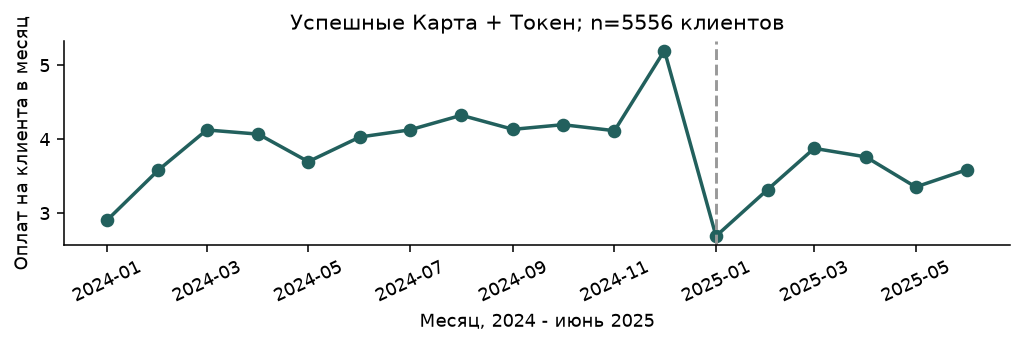

In [2]:
monthly = months.loc[months["client_id"].isin(a["client_id"])].groupby("month")["card_ops"].sum()/len(a)
fig,ax = plt.subplots(figsize=(7.2,2.35),layout="constrained")
ax.plot(pd.to_datetime(monthly.index),monthly,marker="o",color="#22605d",linewidth=1.8)
ax.axvline(pd.Timestamp("2025-01-01"),color="#999999",linestyle="--")
ax.set(title=f"Успешные Карта + Токен; n={len(a)} клиентов",xlabel="Месяц, 2024 - июнь 2025",ylabel="Оплат на клиента в месяц")
ax.tick_params(axis="x",rotation=25)
plt.show()

Состав клиентов во всех месяцах одинаковый. Сравнение одинаковых полугодий уменьшает оценку падения с 15,09% до 8,11%, но не устраняет его. По полутора годам нельзя установить устойчивую годовую сезонность.

### 4.2. Оплаты телефоном выросли, пластиком сократились

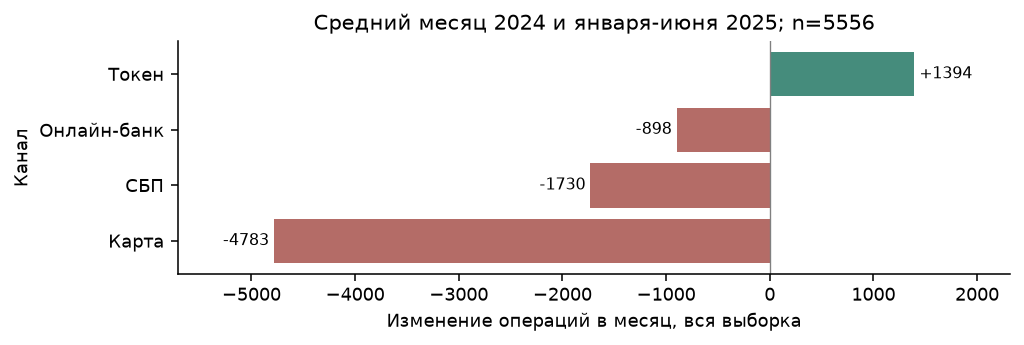

In [3]:
success = ops.loc[ops["status"].eq("успешно") & ops["client_id"].isin(a["client_id"])].copy()
success["year"] = success["txn_datetime"].dt.year
channels = success.groupby(["channel","year"]).size().unstack(fill_value=0)
change = (channels[2025]/6-channels[2024]/12).sort_values()
fig,ax=plt.subplots(figsize=(7.2,2.35),layout="constrained")
ax.barh(change.index,change,color=np.where(change.lt(0),"#b46c67","#458c7c"))
ax.axvline(0,color="gray",linewidth=.7)
ax.set(title=f"Средний месяц 2024 и января-июня 2025; n={len(a)}",xlabel="Изменение операций в месяц, вся выборка",ylabel="Канал")
for i,value in enumerate(change):
    ax.text(value,i,f" {value:+.0f} ",va="center",ha="right" if value<0 else "left",fontsize=8)
ax.margins(x=.15)
plt.show()
attempts=ops.loc[ops["client_id"].isin(a["client_id"]) & ops["channel"].isin(["Карта","Токен"])
    & ops["status"].isin(["успешно","отклонено"])]
attempt_counts=pd.crosstab(attempts["txn_datetime"].dt.year,attempts["status"])

Пластик потерял около 4783 операций в месяц, Токен прибавил 1394. СБП и онлайн-банк тоже сократились. Из 3326 клиентов с карточным падением полная компенсация другими каналами есть у 160, или 4,81%. Общий уход в другие каналы не объясняет все снижение.

Рублевый оборот Карты и Токена снизился с 42,99 до 34,26 млн рублей в месяц, средний чек с 1921 до 1803 рублей. Это показатели всей выборки; состав плативших мог меняться.

<span class="report-page-start"></span>

### 4.3. В выбранных группах карточная частота упала примерно вдвое и сильнее

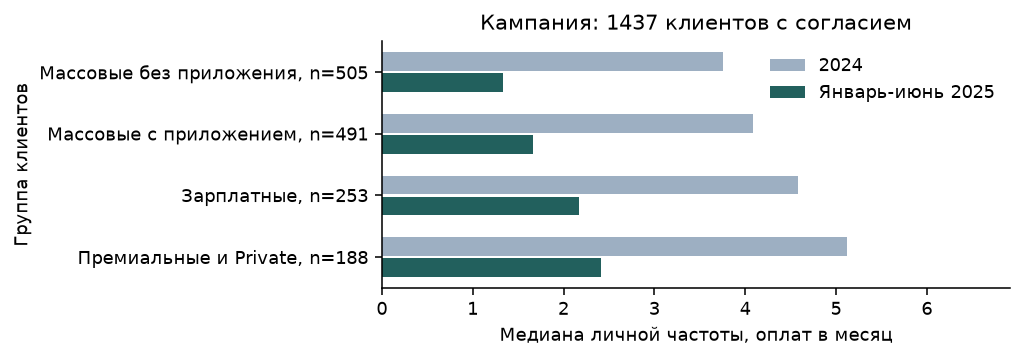

In [4]:
fig,ax=plt.subplots(figsize=(7.2,2.45),layout="constrained")
y=np.arange(len(order))
ax.barh(y-.17,profile["F24"],height=.3,label="2024",color="#9dafc2")
ax.barh(y+.17,profile["F25"],height=.3,label="Январь-июнь 2025",color="#22605d")
ax.set_yticks(y,[f"{label}, n={int(n)}" for label,n in zip(short,profile["N"])])
ax.invert_yaxis()
ax.set(xlabel="Медиана личной частоты, оплат в месяц",ylabel="Группа клиентов",title=f"Кампания: {len(campaign)} клиентов с согласием")
ax.margins(x=.35)
ax.legend(loc="upper right",frameon=False)
plt.show()

Числа относятся к выбранным клиентам с согласием. Медианы личного относительного падения составляют от 49,55% до 65,22%.

### 4.4. У массовых и зарплатных главная потеря в продуктах, у премиальных в досуге

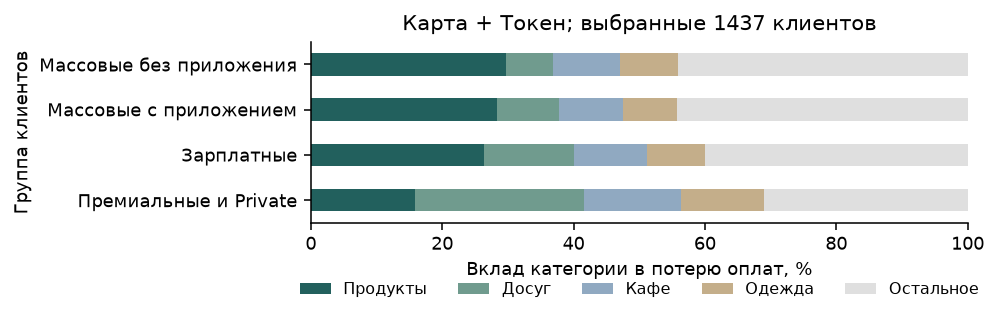

In [5]:
selected_ops = success.merge(campaign,on="client_id",validate="many_to_one")
card_ops = selected_ops.loc[selected_ops["channel"].isin(["Карта","Токен"])]
categories = card_ops.groupby(["group","category","year"],dropna=False).size().unstack(fill_value=0)
loss = (categories[2024]/12-categories[2025]/6).unstack("category").reindex(order)
assert loss.ge(0).all().all() and loss.sum(axis=1).gt(0).all()
parts = loss[["Продукты","Развлечения и досуг","Кафе и рестораны","Одежда и обувь"]].div(loss.sum(axis=1),axis=0)*100
parts.columns=["Продукты","Досуг","Кафе","Одежда"]
parts["Остальное"]=100-parts.sum(axis=1)
ax=parts.set_axis(short).plot.barh(stacked=True,figsize=(7.2,2.5),color=["#22605d","#709b8e","#90a9c1","#c4ae8a","#dfdfdf"])
ax.invert_yaxis()
ax.set(xlabel="Вклад категории в потерю оплат, %",ylabel="Группа клиентов",xlim=(0,100),title=f"Карта + Токен; выбранные {len(campaign)} клиентов")
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.25),ncol=5,frameon=False,fontsize=8)
plt.tight_layout()
plt.show()
assert np.allclose(parts.sum(axis=1),100) and parts.ge(0).all().all()

Продукты дают около 28-30% потери карточных оплат у массовых и 26% у зарплатных. В объединенной группе премиальных и Private наибольший вклад досуга, около 26%. Знаменатель доли: полная потеря числа карточных оплат в месяц внутри каждой группы, включая неизвестную категорию.

Это структура падения, а не установленная причина поведения. В каждой группе в целом сократились и пластик, и Токен; рост Токена на всей базе не означает рост у выбранных клиентов.

<span class="report-page-start"></span>

## 5. Группы для кампании

Во всех четырех группах есть заметное личное снижение карточной частоты и снижение при сравнении одинаковых полугодий. Все клиенты дали согласие и имеют полный период наблюдения. Точные условия приведены в приложении.

Группы не пересекаются по сегменту и наличию приложения.

### Массовые без приложения. Клиентов: 505

Клиенты массового сегмента без банковского приложения. Медиана личного снижения 2,25 оплаты в месяц; медиана снижения в процентах 65,22% относительно 2024 года. В группе сократились оплаты пластиком и телефоном. Наибольшая потеря числа оплат пришлась на продукты.

### Массовые с приложением. Клиентов: 491

Клиенты массового сегмента с банковским приложением. Медиана личного снижения 2,25 оплаты в месяц; медиана снижения в процентах 60,53% относительно 2024 года. В группе сократились оплаты пластиком и телефоном, главная потеря в продуктах. У 308 из 491 клиента последний вход в приложение указан в 2024 году.

### Зарплатные. Клиентов: 253

Клиенты зарплатного сегмента. Медиана личного снижения 2,33 оплаты в месяц; медиана снижения в процентах 50,00% относительно 2024 года. Основная потеря группы в пластике и продуктах. Зачисления зарплаты в этой выгрузке не показаны, поэтому прекращение зарплаты не установлено.

### Премиальные и Private. Клиентов: 188

В группе 151 клиент премиального сегмента и 37 клиентов Private. Медиана личного снижения 2,50 оплаты в месяц; медиана снижения в процентах 49,55% относительно 2024 года. В объединенной группе сократились оплаты пластиком и телефоном, наибольшая потеря числа оплат пришлась на досуг.

Всего отобраны 1437 клиентов из допустимых 2000, свободно 563 места. У двух зарплатных клиентов рост оплат в других каналах компенсировал карточное снижение; они соответствуют правилу отбора по картам.


<span class="report-page-start"></span>

## 6. Кого не включаем и почему

In [6]:
conditions = [metrics["marketing_opt_in"].ne("Да"), ~metrics["comparable"],
    metrics["declined"].eq(False).fillna(False), ~metrics["decline_both_windows"].fillna(False),
    ~metrics["segment"].isin(["Массовый","Зарплатный","Премиальный","Private"])]
reason = np.select([c.fillna(False).to_numpy(dtype=bool) for c in conditions],
    ["Нет согласия","Неполная история","Нет снижения","Недостаточное снижение или нет снижения при сравнении первых полугодий","Неизвестный сегмент"],default="В кампании")
exclusions = pd.Series(reason).value_counts().reindex(["Нет согласия","Неполная история","Нет снижения","Недостаточное снижение или нет снижения при сравнении первых полугодий","Неизвестный сегмент","В кампании"])
display(HTML(exclusions.rename_axis("Причина").reset_index(name="Клиентов").to_html(index=False)))
assert exclusions.sum()==len(metrics) and exclusions["В кампании"]==len(campaign)

Причина,Клиентов
Нет согласия,635
Неполная история,105
Нет снижения,1967
Недостаточное снижение или нет снижения при сравнении первых полугодий,1522
Неизвестный сегмент,2
В кампании,1437


Причины применены сверху вниз, каждый из 5668 клиентов учтен один раз. Поздних клиентов во всей базе 112, но после исключения без согласия в строке неполной истории осталось 105. Неизвестный город не мешает отбору, город не участвует в правиле.

Еще 332 клиента есть в операциях, но отсутствуют в справочнике. Их признаки и согласия неизвестны; эти клиенты не входят ни в кампанию, ни в знаменатель 5668.

## 7. Что проверили и что не подтвердилось

- Проверили, не связано ли падение только с длиной периодов. В основном расчете число оплат за 2024 год делим на 12, за январь-июнь 2025 на 6. У одних и тех же 5556 клиентов частота снизилась с 4,04 до 3,43 оплаты в месяц, на 15,09%.
- Проверили, не объясняется ли падение тем, что полный год включает другие месяцы. Дополнительно сравнили январь-июнь 2024 и 2025 годов на той же выборке: частота снизилась с 3,74 до 3,43 оплаты в месяц, на 8,11%. Падение сохраняется и при сравнении одинаковых месяцев.
- Все перешли в другие каналы: полная компенсация есть у 160 из 3326 снизивших, или 4,81%.
- Общий рост доли отказов: 5529 из 275128 попыток в 2024 (2,010%) против 2283 из 116746 в январе-июне 2025 (1,956%); возвраты не входят в попытки.
- Сильная монотонная связь с доходом: Спирмен +0,090 по 4827 пригодным парам, связь слабая.


<span class="report-page-start report-appendix-start"></span>

## 8. Приложение

### 8.1. Сводка журнала изменений

In [7]:
def changed(field,issue):
    return int(log.loc[log["field"].eq(field)&log["issue"].eq(issue),"n_rows"].sum())

iqr=log.loc[log["issue"].eq("IQR для описательных расчётов"),["scope","n_rows"]].copy()
iqr["Ряд"]=iqr["scope"].str.split(";").str[0]
iqr=iqr.set_index("Ряд")["n_rows"]
selection=log.loc[log["field"].eq("transactions_analysis.*")].iloc[0]
summary=pd.DataFrame([
 ["clients.*, txn_id","Копии клиентов / операций; неполные даты",f"{changed('clients.*','Полные копии')}; {changed('transactions.*','Полные копии')}; {changed('transactions.*','Разная точность даты')}","Лишние строки удалены после сверки полей и дня"],
 ["city, category","Разные написания",f"{changed('clients.city','Разные написания')}; {changed('transactions.category','Разные написания')}","Проверенные названия объединены по словарю"],
 ["city, segment",f"Противоречивые поля {int(metrics['client_record_conflict'].sum())} клиентов",f"{changed('clients.city','Противоречивые записи')}; {changed('clients.segment','Противоречивые записи')}","Поля стали NA, сами клиенты сохранены"],
 ["monthly_income","Код -999 и малые доходы",f"{changed('clients.monthly_income','Техническое обозначение неизвестного дохода')}; {int(metrics['income_suspicious_low'].sum())}","Код стал NA; малые суммы сохранены с флагом и исключены из статистики дохода"],
 ["income_source","Не указан",changed('clients.income_source','Источник зарплаты не указан'),"Заменено на NA: источник зарплаты неизвестен"],
 ["app_last_login","Месяц раньше регистрации",changed('clients.app_last_login','Месяц входа раньше регистрации'),"Заменен на NaT, причина сохранена"],
 ["satisfaction_score","Нет ответа на опрос",changed('clients.satisfaction_score','Пустая ячейка'),"Ответы не выдумывали; состав ответивших отличается от базы"],
 ["category, mcc_code","Несогласованная пара",f"{changed('transactions.category','Категория не подтверждена парой с MCC')}; в анализе {ops['category'].isna().sum()}","Категория стала NA; MCC, сумма и операция сохранены"],
 ["Выборка операций","Вне периода или без клиента в справочнике",int(selection['n_rows']),f"В анализе {len(ops)} из {selection['value_before']} отдельных операций; полная таблица сохранена"],
 ["monthly_income, amount","За границами IQR",f"{iqr['Доход, RUB']}; RUB {iqr['Операция, RUB']}; USD {iqr['Операция, USD']}; EUR {iqr['Операция, EUR']}","Суммы сохранены; IQR применяется только к показанным распределениям"]],
 columns=["Поле","Что нашли","Строк","Что сделали"])
assert len(log)==45 and len(summary)==10
display(HTML(summary.to_html(index=False,classes="cleaning-summary")))


Поле,Что нашли,Строк,Что сделали
"clients.*, txn_id",Копии клиентов / операций; неполные даты,41; 1306; 194,Лишние строки удалены после сверки полей и дня
"city, category",Разные написания,1609; 50906,Проверенные названия объединены по словарю
"city, segment",Противоречивые поля 14 клиентов,28; 18,"Поля стали NA, сами клиенты сохранены"
monthly_income,Код -999 и малые доходы,56; 182,Код стал NA; малые суммы сохранены с флагом и исключены из статистики дохода
income_source,Не указан,1466,Заменено на NA: источник зарплаты неизвестен
app_last_login,Месяц раньше регистрации,21,"Заменен на NaT, причина сохранена"
satisfaction_score,Нет ответа на опрос,3396,Ответы не выдумывали; состав ответивших отличается от базы
"category, mcc_code",Несогласованная пара,1562; в анализе 1486,"Категория стала NA; MCC, сумма и операция сохранены"
Выборка операций,Вне периода или без клиента в справочнике,28171,В анализе 586526 из 614697 отдельных операций; полная таблица сохранена
"monthly_income, amount",За границами IQR,380; RUB 45416; USD 92; EUR 84,Суммы сохранены; IQR применяется только к показанным распределениям


### 8.2. Методика

Учитываем операции клиентов из справочника за 01.01.2024-30.06.2025. N24 и N25: успешные оплаты Карта + Токен во всех валютах за 2024 и январь-июнь 2025. F24=N24/12; F25=N25/6; delta=F25-F24; относительное изменение=F25/F24-1 при F24>0. Месяцы без оплат входят в расчет с нулем.

Сравнимая выборка: 5556 клиентов с registration_date<=01.01.2024. Для кампании одновременно нужны согласие, delta<=-1, F25/F24<=0,70 и N25<N24_H1, где N24_H1: число оплат за январь-июнь 2024. Профили: Массовый + приложение Нет; Массовый + Да; Зарплатный; Премиальный или Private. Группы не пересекаются.

Общую частоту считаем средним по сравнимым клиентам, типичного клиента описываем медианой, разброс через Q1 и Q3: большие значения сдвигают среднее. Доходы с NA или флагом низкой суммы исключены из доходной статистики; механизм пропусков не установлен. Денежные итоги только в RUB; отказы и возвраты сохранены отдельно. В журнале 45 правил.

Проверки ниже выполнены на 5556 клиентах. Три p приведены после поправки Бонферрони, то есть умножения на 3.

- Критерий знаков сравнивает число снижений и ростов: 3326 против 2058, еще 172 без изменения; p=6,09e-67. Снижение встречается чаще роста.
- Хи-квадрат проверяет связь приложения с долей снизившихся: хи2=52,925, V Крамера=0,098, p=1,04e-12. Доли различаются, сила связи небольшая.
- 10000 перестановок проверяют разницу среднего изменения с приложением и без: +0,384 оплаты в месяц, p=0,000300. У клиентов с приложением среднее изменение выше.
- Бутстреп, 2000 повторов, оценивает неопределенность среднего изменения: -0,610 оплаты в месяц, 95%-й интервал [-0,660; -0,560]. Весь интервал ниже нуля.
- Спирмен оценивает связь изменения частоты с доходом и возрастом: +0,090 по 4827 парам и -0,076 по 5556 парам соответственно. Обе связи слабые.


### 8.3. Использование ИИ

- Значительная часть кода и графиков доработана с помощью ИИ: он дополнял исходные наброски, переписывал и упрощал код и улучшал оформление.
- ИИ помог упорядочить оформление ноутбука и убрать черновые ячейки.
- Полученные результаты я разбирал самостоятельно и записывал выводы под ячейками. ИИ помог структурировать готовые выводы и оформить их в сводные таблицы.
